# Task 3 – Sound Data Collection and Processing

**Owner:** Santhiana
**Reads:** `data/audio/raw/<member>/` (each member says *"Yes, approve"* and *"Confirm transaction"*)
**Writes:** `data/audio/processed/` (cleaned clips and `audio_features.csv`) and `data/audio/augmented/`

The cleaning, augmentation and feature extraction are done by `src/audio_pipeline.py` (`python src/audio_pipeline.py`). This notebook looks at the raw recordings, plots and interprets them, and checks the feature file the pipeline produced.

In [1]:
import sys
import librosa

print(sys.version)
print(librosa.__version__)

3.14.6 | packaged by Anaconda, Inc. | (main, Jul  9 2026, 14:29:05) [MSC v.1942 64 bit (AMD64)]
1.0.0


## 1. Load the recordings of every member

In [2]:
from pathlib import Path

import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_DIR = Path.cwd()

if not (PROJECT_DIR / "data").exists():
    PROJECT_DIR = PROJECT_DIR.parent

RAW_DIR = PROJECT_DIR / "data/audio/raw"   # every member's folder
PROCESSED_DIR = PROJECT_DIR / "data/audio/processed"

audio_files = sorted(p for p in RAW_DIR.rglob("*") if p.suffix.lower() in (".wav", ".mp3"))

print("Number of original recordings:", len(audio_files))

for file in audio_files:
    audio, sr = librosa.load(file, sr=None)
    print(f"{file.parent.name.lower()} / {file.name}:")
    print(f"  Sample rate: {sr} Hz")
    print(f"  Duration: {len(audio) / sr:.2f} seconds")

Number of original recordings: 6


peggy / peggy_confirm_transaction.wav:
  Sample rate: 48000 Hz
  Duration: 2.79 seconds
peggy / peggy_yes_approve.wav:
  Sample rate: 48000 Hz
  Duration: 3.93 seconds
santhiana / santhiana_confirm_transaction.wav:
  Sample rate: 16000 Hz
  Duration: 2.75 seconds
santhiana / santhiana_yes_approve.wav:
  Sample rate: 16000 Hz
  Duration: 2.93 seconds
shema / Shema_ yes_approve.mp3:
  Sample rate: 44100 Hz
  Duration: 2.25 seconds
shema / Shema_confirm_transaction.mp3:
  Sample rate: 44100 Hz
  Duration: 1.99 seconds


**Result:** 6 recordings, 2 per member, between 2.0 and 3.9 seconds long. Jonathan's are still missing.

They come from **three different setups:**
- **Peggy:** 48 kHz WAV
- **Santhiana:** 16 kHz WAV
- **Shema:** 44.1 kHz MP3

**Decision:** the pipeline loads every clip as **16 kHz mono**, so all clips share one format before any feature is computed. It then trims silence (anything 25 dB below the peak) and normalises the volume, so that distance from the microphone is not a cue.

## 2. Waveforms

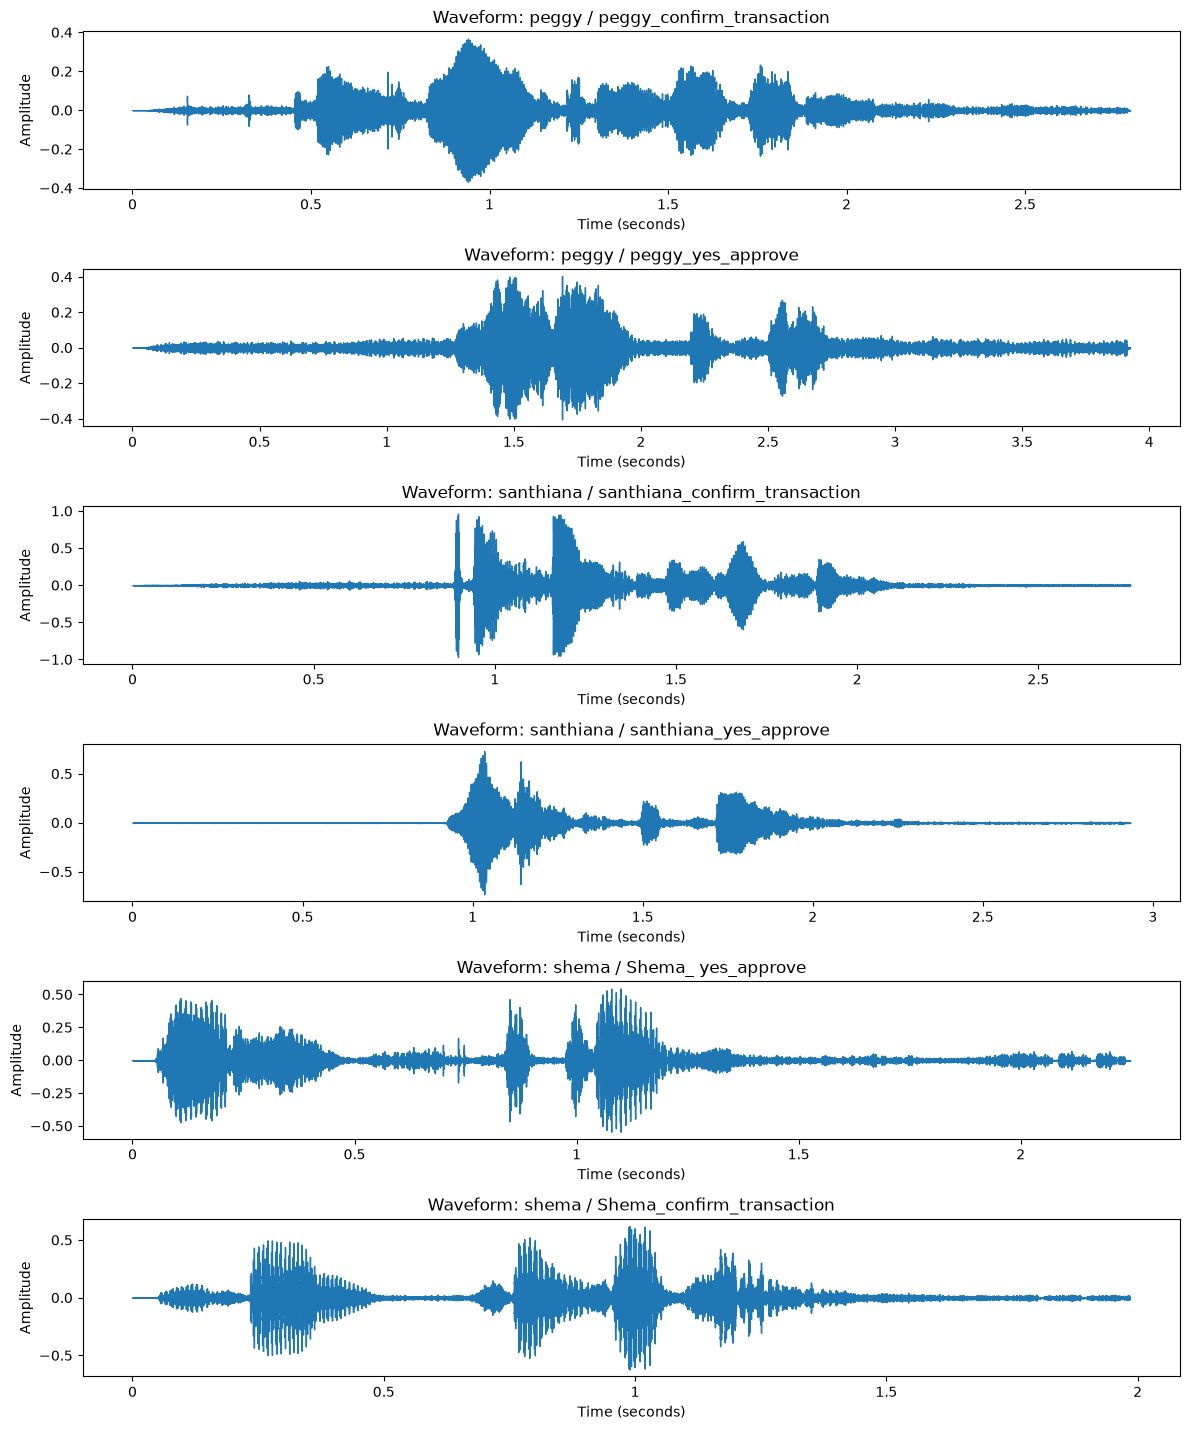

In [3]:
fig, axes = plt.subplots(len(audio_files), 1, figsize=(12, 2.4 * len(audio_files)))

if len(audio_files) == 1:
    axes = [axes]

for ax, file in zip(axes, audio_files):
    audio, sr = librosa.load(file, sr=None)

    librosa.display.waveshow(audio, sr=sr, ax=ax)
    ax.set_title(f"Waveform: {file.parent.name.lower()} / {file.stem}")
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("Amplitude")

plt.tight_layout()
plt.show()

**What the waveforms show:**
- **Syllables:** each burst is a syllable. *"Yes, approve"* shows 3–4 bursts, and *"Confirm transaction"* 4–5.
- **Peggy:** her clips have a steady low hiss before and after speaking. Her phone picked up background noise, and her loudest peaks are about 0.4.
- **Santhiana:** near-silent before she starts (about 0.9 s), and her peaks reach almost ±1. Her recordings are the loudest and cleanest.
- **Shema:** speech starts almost at once, the clips are the shortest (about 2 s), and the very regular spikes show strongly voiced, steady-pitch speech.
- **Trimming:** the long silences at the start (Peggy, Santhiana) are why the pipeline trims silence before extracting features.

## 3. Spectrograms

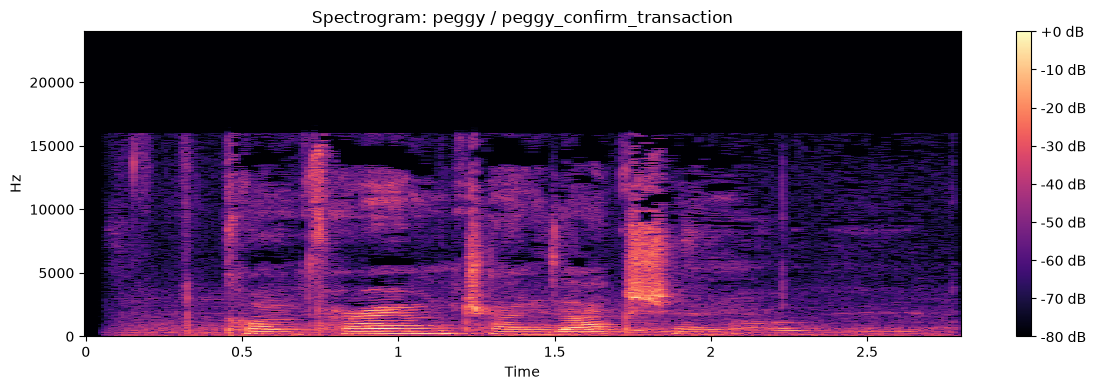

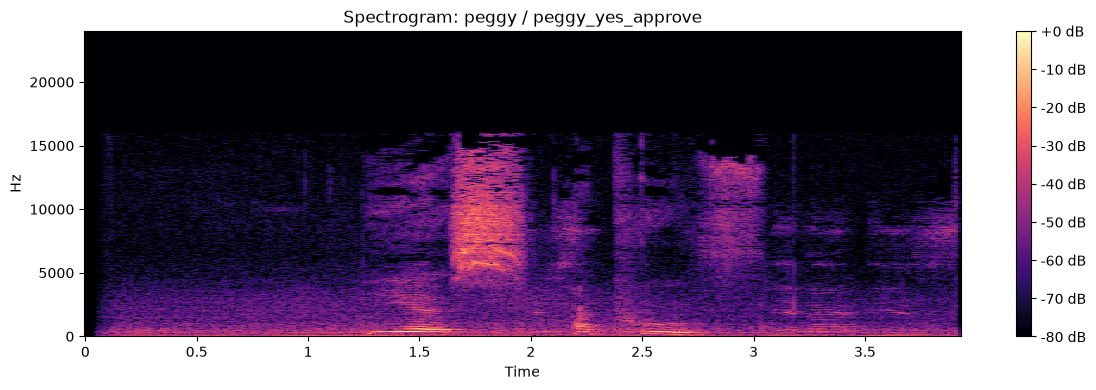

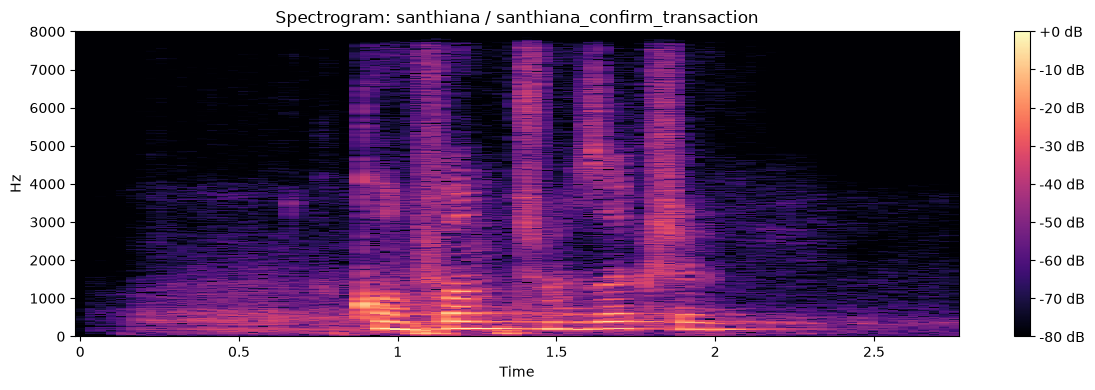

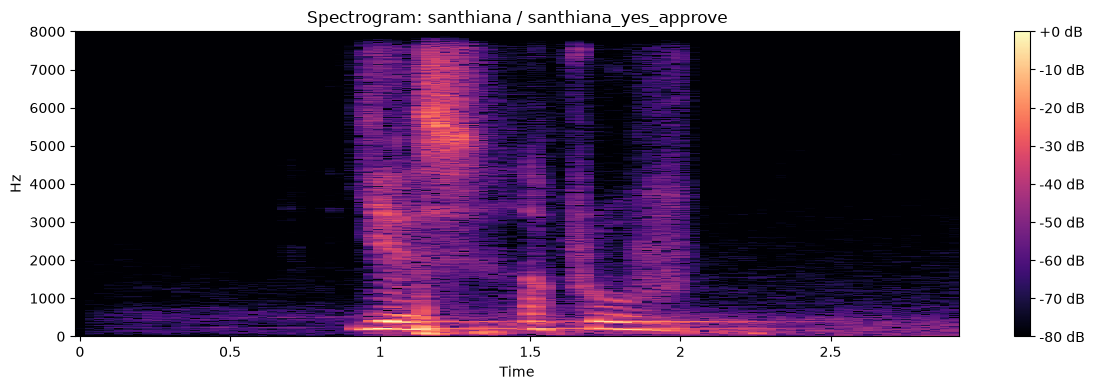

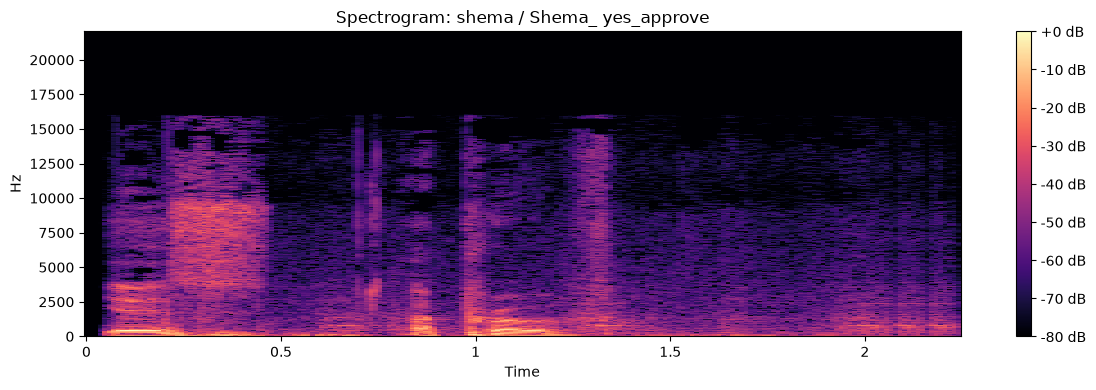

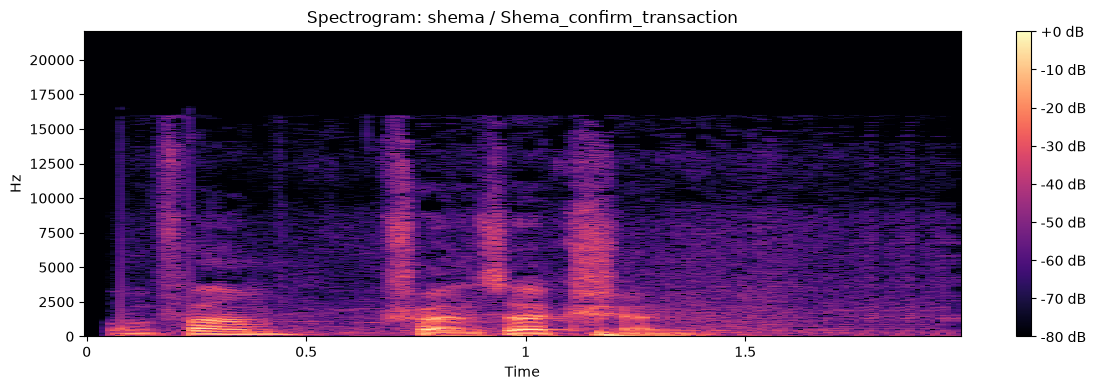

In [4]:
for file in audio_files:
    audio, sr = librosa.load(file, sr=None)

    D = librosa.amplitude_to_db(
        np.abs(librosa.stft(audio)),
        ref=np.max
    )

    plt.figure(figsize=(12, 4))

    librosa.display.specshow(
        D,
        sr=sr,
        x_axis="time",
        y_axis="hz"
    )

    plt.colorbar(format="%+2.0f dB")
    plt.title(f"Spectrogram: {file.parent.name.lower()} / {file.stem}")
    plt.tight_layout()
    plt.show()

**What the spectrograms show** (time across, frequency up, brightness = energy):
- **Voice pitch:** the bright horizontal bands below about 1,000 Hz are the voice's harmonics, set by each speaker's pitch.
- **Hiss sounds:** tall vertical bands reaching high frequencies are the "s", "t", "f" and "sh" sounds (for example the "s" of *yes* in Shema's clip, and the "tr" and "-ction" in Santhiana's).
- **Recording setup:** Peggy's and Shema's spectrograms stop sharply at 16,000 Hz, which is typical of phone audio compression. Santhiana's stop at 8,000 Hz, because her file is 16 kHz. Peggy's also show the background hiss as a faint layer at every frequency.
- **What the features see:** after the pipeline's resampling to 16 kHz, every clip only keeps up to 8,000 Hz, so the different cut-offs disappear. The differences in background noise remain, though. This is a known weakness: with so few recordings, the voice model may partly learn each person's recording setup rather than their voice.

## 4. Augmentation and features

`audio_pipeline.py` makes **5 augmented copies** of every cleaned clip:

| Augmentation | Setting | Simulates |
|---|---|---|
| `pitch_up` / `pitch_down` | ±1 semitone | a slightly higher or lower voice; kept small so a voice doesn't turn into another member's |
| `faster` / `slower` | ×1.05 / ×0.95 speed | speaking faster or slower |
| `background_noise` | Gaussian noise, σ = 0.005 | a noisy room |

Every clip, original or augmented, becomes **34 features**:
- **13 MFCCs (mean and standard deviation):** the shape of the vocal tract, the classic voiceprint feature.
- **Spectral roll-off:** the frequency below which 85% of the energy lies.
- **RMS energy:** loudness.
- **Spectral centroid:** how bright the voice sounds.
- **Zero-crossing rate:** how noisy or hissy it is.

Roll-off, energy, centroid and zero-crossing rate each have a mean and a standard deviation over time.

In [5]:
features_path = PROCESSED_DIR / "audio_features.csv"
features = pd.read_csv(features_path)

print("Feature dataset shape:", features.shape)
display(features.head())

print("\nFeature columns:")
print(features.columns.tolist())

print("\nMissing values:")
print(features.isnull().sum().sum())

print("\nAugmentation counts:")
print(features["variant"].value_counts())

Feature dataset shape: (36, 38)


,speaker,utterance,variant,filename,mfcc_1_mean,mfcc_1_std,mfcc_2_mean,mfcc_2_std,mfcc_3_mean,mfcc_3_std,...,mfcc_13_mean,mfcc_13_std,rolloff_mean,rolloff_std,rms_mean,rms_std,centroid_mean,centroid_std,zcr_mean,zcr_std
0,peggy,peggy_confirm_transaction,clean,peggy_confirm_transaction_clean.wav,-167.887085,70.681374,103.426926,44.836658,5.842264,25.453459,...,0.660705,6.041578,3213.671875,1472.473930,0.103911,0.076953,1588.121011,795.156037,0.095868,0.074981
1,peggy,peggy_confirm_transaction,pitch_up,peggy_confirm_transaction_pitch_up.wav,-150.908722,70.547203,97.926712,42.707348,3.854378,27.205942,...,-6.034691,7.434995,3430.468750,1398.514750,0.108259,0.089579,1686.763340,777.804723,0.116309,0.094682
2,peggy,peggy_confirm_transaction,pitch_down,peggy_confirm_transaction_pitch_down.wav,-154.094635,73.073586,108.213242,41.139084,0.883072,22.256248,...,-2.348421,8.479892,3095.312500,1319.286653,0.124732,0.094100,1511.122936,725.654033,0.093909,0.086971
3,peggy,peggy_confirm_transaction,faster,peggy_confirm_transaction_faster.wav,-163.687271,74.784943,99.133034,43.203266,6.480505,24.818380,...,-0.426811,5.632017,3387.746711,1427.902814,0.100494,0.075251,1651.513437,783.549846,0.103882,0.090111
4,peggy,peggy_confirm_transaction,slower,peggy_confirm_transaction_slower.wav,-148.402176,72.357964,97.609482,43.352867,6.249029,25.081936,...,-1.559912,5.475460,3434.523810,1435.402249,0.115191,0.089238,1673.243479,774.047032,0.106422,0.091162



Feature columns:
['speaker', 'utterance', 'variant', 'filename', 'mfcc_1_mean', 'mfcc_1_std', 'mfcc_2_mean', 'mfcc_2_std', 'mfcc_3_mean', 'mfcc_3_std', 'mfcc_4_mean', 'mfcc_4_std', 'mfcc_5_mean', 'mfcc_5_std', 'mfcc_6_mean', 'mfcc_6_std', 'mfcc_7_mean', 'mfcc_7_std', 'mfcc_8_mean', 'mfcc_8_std', 'mfcc_9_mean', 'mfcc_9_std', 'mfcc_10_mean', 'mfcc_10_std', 'mfcc_11_mean', 'mfcc_11_std', 'mfcc_12_mean', 'mfcc_12_std', 'mfcc_13_mean', 'mfcc_13_std', 'rolloff_mean', 'rolloff_std', 'rms_mean', 'rms_std', 'centroid_mean', 'centroid_std', 'zcr_mean', 'zcr_std']

Missing values:
0

Augmentation counts:
variant
clean               6
pitch_up            6
pitch_down          6
faster              6
slower              6
background_noise    6
Name: count, dtype: int64


**Result:** 6 recordings × 6 versions (clean + 5 augmentations) = **36 rows**, with 4 label columns and **34 features**, and **no missing values**.

## 5. How do the augmentations change the features?

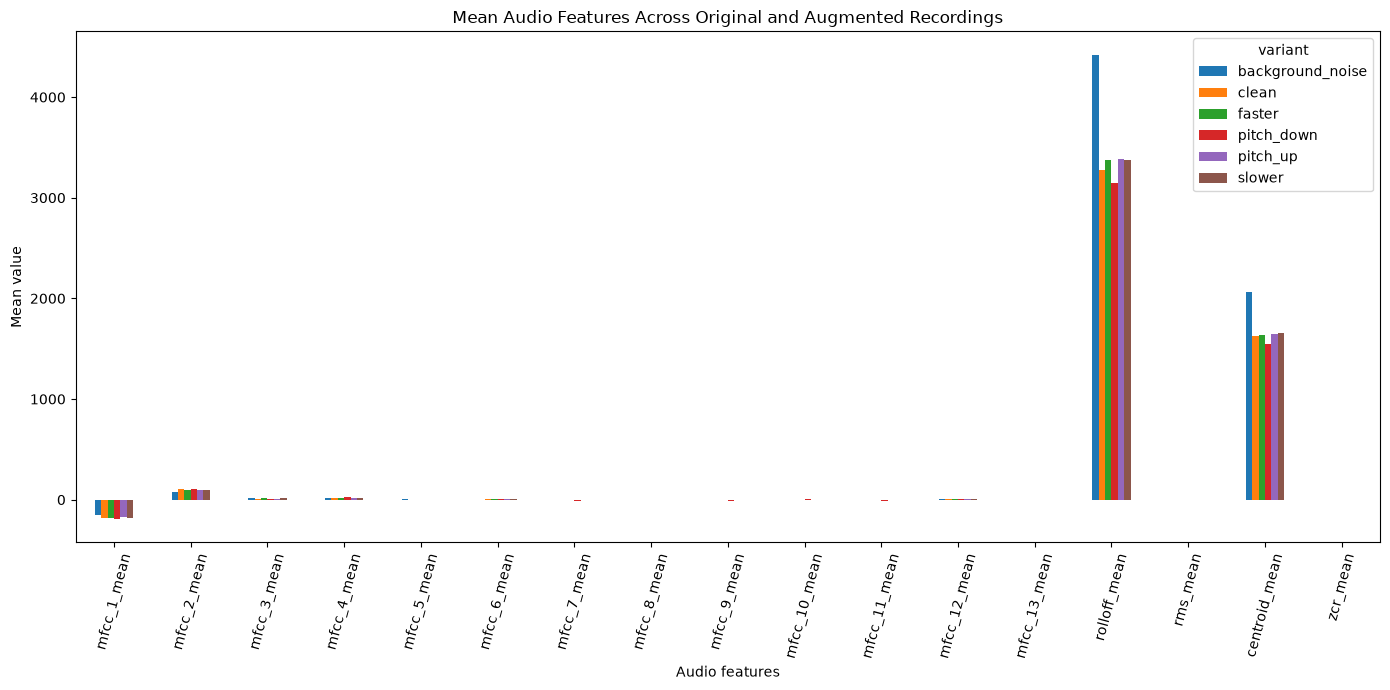

In [6]:
feature_columns = [
    col for col in features.columns
    if col.endswith("_mean")
]

features.groupby("variant")[feature_columns].mean().T.plot(
    figsize=(14, 7),
    kind="bar"
)

plt.title("Mean Audio Features Across Original and Augmented Recordings")
plt.xlabel("Audio features")
plt.ylabel("Mean value")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

**What it shows:**
- **Scale:** the plot is dominated by roll-off and centroid, which are measured in Hz (thousands), so the MFCCs and the small energy and zero-crossing values look flat. This is also why the models scale features before Logistic Regression.
- **Background noise changes the features most:** average roll-off rises from about 3,300 Hz (clean) to about 4,400 Hz, and centroid from about 1,600 to 2,050 Hz. Noise adds energy at high frequencies, which makes the voice look brighter.
- **Pitch and speed copies stay close to the clean values,** with pitch down lowering the roll-off slightly. They add variety without changing who is speaking.

## 6. Do the speakers differ?

In [7]:
# Compare the speakers on their clean (non-augmented) recordings
clean = features[features["variant"] == "clean"]
clean.groupby("speaker")[["mfcc_1_mean", "mfcc_2_mean", "rolloff_mean", "centroid_mean", "zcr_mean", "rms_mean"]].mean().round(3)

,mfcc_1_mean,mfcc_2_mean,rolloff_mean,centroid_mean,zcr_mean,rms_mean
speaker,,,,,,
peggy,-173.433,101.306,3431.187,1702.065,0.116,0.095
santhiana,-224.878,105.713,2791.753,1425.510,0.093,0.098
shema,-150.088,97.061,3608.870,1749.480,0.124,0.105


**Result:**
- **Santhiana's voice is the darkest:** lowest roll-off (about 2,790 Hz) and centroid (about 1,430 Hz), and the lowest first MFCC (about −225).
- **Peggy and Shema are closer:** roll-off about 3,430 and 3,610 Hz.

So the features do separate the speakers on average. But with only 2 recordings each, these averages rest on very few clips. That's the main reason the voice model is much weaker than the face model.

## Summary
- **Collected:** 2 phrases each from 3 members (Jonathan's pending), plotted as waveforms and spectrograms, with interpretation.
- **Cleaned:** 16 kHz mono, silence trimmed, volume normalised.
- **Augmented:** 5 copies per clip (pitch ±1, speed ×1.05 and ×0.95, background noise).
- **Features:** 34 per clip (MFCCs, roll-off, energy, centroid, ZCR), saved to `data/audio/processed/audio_features.csv`.
- **Watch out:** members used different recording setups. More takes per person, on similar devices, would make the voiceprint more reliable.